# Laplace–Beltrami invariance (Phase 3, step 1)

**Question.** Which invariances does the Laplace–Beltrami spectrum of a lesion surface really have, do they survive the
voxel pipeline on TDSC-ABUS, and does our previous work [Barekatrezaei et al. 2026, doi:10.1016/j.eswa.2025.129973] use them?

**Short answer.**

- Rigid motion, scale (after multiplying by area) and isometry are provable and hold to solver precision on meshes.
- On re-voxelised lesions they hold to about 0.2% with smoothed surfaces and about 1% with staircase surfaces.
- The eigenvalues of `L` alone, used in our previous work, are approximately $\lambda\cdot\text{Area}/n$, with $n$ the vertex count. They are not shape features: they rank lesions by vertex count, and so by size.
- With size removed, the first 20 eigenvalues carry much less signal here (cross-validated AUC 0.59, against 0.71 for volume). This does not yet rule out higher modes.

This covers invariance only. What the spectrum determines, Hersch's bound and stability are later roadmap steps. How to rerun: [`docs/reproductions/lb-invariance.md`](../docs/reproductions/lb-invariance.md).

## 1. Theory

Let $(S,g)$ be a closed surface. The eigenproblem $-\Delta_g\phi=\lambda\phi$ has the variational form
$$\lambda_k=\min_{V_k}\max_{\phi\in V_k}\frac{\int_S|\nabla_g\phi|_g^2\,dA_g}{\int_S\phi^2\,dA_g},\qquad \dim V_k=k+1,$$
which uses only the metric $g$.

**Proposition 1 (isometry, which includes rigid motion).** If $f:S\to S'$ is an isometry, $f^*g'=g$, then $\lambda_k(S')=\lambda_k(S)$ for all $k$.
*Proof.* $\phi\mapsto\phi\circ f$ is a bijection of test functions. It preserves $dA$ and $|\nabla\phi|$, hence every Rayleigh quotient and the min-max values. A rigid motion restricted to $S$ is an isometry. $\square$

**Proposition 2 (scale).** For $S'=cS$: $\lambda_k(S')=\lambda_k(S)/c^2$ and $\text{Area}(S')=c^2\text{Area}(S)$, so $\lambda_k\cdot\text{Area}$ is scale-invariant.
*Proof.* $g'=c^2g$ multiplies $|\nabla\phi|^2$ by $c^{-2}$ and $dA$ by $c^2$. The Rayleigh quotient's numerator is unchanged and its denominator gains $c^2$. $\square$

**Discrete versions.** With cotangent weights and a lumped mass, $L\phi=\lambda M\phi$:

- Cotangents and triangle areas are functions of edge lengths alone. So any map that preserves every edge length preserves $L$ and $M$ exactly, and Proposition 1 holds exactly, including on a surface that is bent rather than moved.
- Under $x\mapsto cx$, cotangents are unchanged and $M\mapsto c^2M$, so Proposition 2 holds exactly.

**Proposition 3 (eigenvalues of $L$ alone).** $L$ is unchanged by scaling, and if the mass is near uniform, $M\approx\frac{\text{Area}}{n}I$, then
$$\operatorname{eig}_k(L)\approx\lambda_k\cdot\frac{\text{Area}}{n}.$$
*Derivation (approximation, not a bound).* Substitute that $M$ into $L\phi=\lambda M\phi$. So $\operatorname{eig}_k(L)$ is a scale-free shape number divided by the vertex count. On voxel meshes $n$ grows with lesion size and with grid resolution, which predicts that these values track size and change with the grid. Section 4 tests this.

**A limit that follows from Proposition 1.** Mirroring a cap of a sphere through its cutting plane is an isometry, so the dented solid has the same spectrum as the sphere, with a smaller volume. The spectrum alone cannot separate a bulge from a dent of this kind.

## 2. Implementation details

| Choice | Ours | Why |
|---|---|---|
| Operator | Cotangent $L$, lumped $M$, $L\phi=\lambda M\phi$ (`lb_spectrum`, `compute_laplace_beltrami_operator`) | Converges to the smooth operator under the conditions in Hildebrandt et al. 2006 |
| Normalisation | $\lambda_k\cdot\text{Area}$ | Proposition 2 |
| Comparison | Eigenvalues of $L$ alone | What our previous work uses (its Eq. 3-4; `lesion_cache.lb_eigenvalues`) |
| Motions | 5 random rotations plus shifts under half a voxel, per lesion, seeded | All five are interpolated, so no render is favoured |
| Grid | Isotropic 0.4 mm; motion 0 repeated at 0.8 mm | Rotation needs an isotropic grid; the native grid is 0.2 × 0.073 × 0.476 mm |
| Surfaces | Staircase: marching cubes on the binary mask. Smoothed: Gaussian $\sigma$ = 0.8 mm first | Staircase is what the current pipeline does. Smoothing may also erase real spiculation, which is not tested here |
| Pieces | Largest mesh piece only | Each extra piece adds a zero eigenvalue and shifts every index |
| Lesions | All 200 for invariance. Labels used on Train+Validation (130) only | Test stays unused while descriptors are designed |
| Modes | $k=1,\dots,20$ | Enough to test invariance; higher modes are an open question |

Agreement across motions is ICC(1,1) on log values: the share of variance that is between lesions. Values near 1 mean a motion changes a lesion less than lesions differ from each other.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from abus_classification.features.shape_descriptor.shape_descriptors import lb_spectrum
from abus_classification.protocol import auc_ci
from test.utils_tests.features_tests.test_signature import dimpled_sphere

d = np.load("../results/lb-invariance/spectra.npz")
lam, lam_l, area, volume, n = d["lam"], d["lam_l"], d["area"], d["volume"], d["vertices"]
eswa, native_n = d["eswa_lb"], d["native_vertices"]
na = lam * area[..., None]                       # (lesion, surface, render, k); render 5 is the coarse grid
STAIR, SMOOTH, COARSE = 0, 1, 5
BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})

## 3. Verification

Unit tests in `test/utils_tests/features_tests/test_signature.py` check the analytic sphere spectrum, rigid and scale invariance, the dent, a stretch that must change the spectrum, Proposition 3 on icospheres, and a moved voxel ball against $8\pi$. The exact isometry from Section 1:

volume: sphere 4.147, dented 3.281; area: 12.504, 12.504
largest relative spectrum change: dent 2.9e-15, stretch 0.23


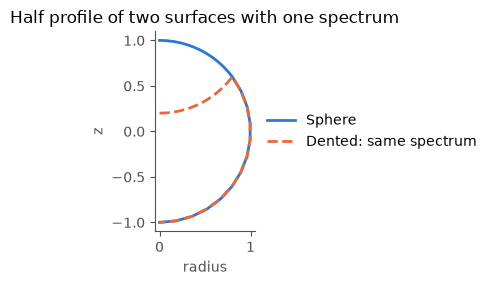

In [2]:
sphere, dented = dimpled_sphere()
s, t = lb_spectrum(sphere, 12)[1:], lb_spectrum(dented, 12)[1:]
stretched = sphere.copy(); stretched.vertices = stretched.vertices * [1, 1, 1.5]
print(f"volume: sphere {sphere.volume:.3f}, dented {dented.volume:.3f}; area: {sphere.area:.3f}, {dented.area:.3f}")
print(f"largest relative spectrum change: dent {np.abs(t / s - 1).max():.1e}, stretch {np.abs(lb_spectrum(stretched, 12)[1:] / s - 1).max():.2f}")
fig, ax = plt.subplots(figsize=(6.5, 2.6)); ax.grid(False)
for m, c, name, ls in ((sphere, BLUE, "Sphere", "-"), (dented, ORANGE, "Dented: same spectrum", "--")):
    r = np.hypot(m.vertices[:, 0], m.vertices[:, 1]); keep = np.isclose(np.arctan2(m.vertices[:, 1], m.vertices[:, 0]), 0)
    o = np.argsort(np.arccos(np.clip(sphere.vertices[keep, 2], -1, 1)))
    ax.plot(r[keep][o], m.vertices[keep, 2][o], ls, color=c, lw=2, label=name)
ax.set(aspect="equal", xlabel="radius", ylabel="z", title="Half profile of two surfaces with one spectrum"); ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, .5)); plt.show()

## 4. Results

### Mesh quality

In [3]:
pd.DataFrame({"Share with more than one mesh piece": (d["pieces"][:, :, :5] > 1).mean((0, 2)),
              "Share genus 0 (largest piece)": (d["euler"][:, :, :5] == 2).mean((0, 2)),
              "Median Euler number": np.median(d["euler"][:, :, :5], (0, 2)),
              "Median vertices": np.median(n[:, :, :5], (0, 2))}, index=["Staircase", "Smoothed"]).round(3)

,Share with more than one mesh piece,Share genus 0 (largest piece),Median Euler number,Median vertices
Staircase,0.430,0.052,-26.0,6788.5
Smoothed,0.051,0.963,2.0,4554.0


Staircase surfaces are rarely genus 0 and often fall into pieces. That matters for Hersch's bound and spherical harmonics, which both need genus 0.

### Rigid motion on re-voxelised lesions

In [4]:
def icc(x):
    x = np.log(x); m = x.shape[1]; g = x.mean(1)
    between, within = m * g.var(ddof=1), ((x - g[:, None]) ** 2).sum() / (x.shape[0] * (m - 1))
    return (between - within) / (between + (m - 1) * within)
ks = [1, 2, 5, 10, 20]; rows = {}
for s, name in ((STAIR, "Staircase"), (SMOOTH, "Smoothed")):
    x = na[:, s, :5]; l = lam_l[:, s, :5]
    rows[name + ", λ·Area: median CV"] = [np.median(x[:, :, k].std(1) / x[:, :, k].mean(1)) for k in ks]
    rows[name + ", λ·Area: ICC"] = [icc(x[:, :, k]) for k in ks]
    rows[name + ", eig(L): median CV"] = [np.median(l[:, :, k].std(1) / l[:, :, k].mean(1)) for k in ks]
pd.DataFrame(rows, index=[f"k={k}" for k in ks]).T.round(3)

,k=1,k=2,k=5,k=10,k=20
"Staircase, λ·Area: median CV",0.010,0.010,0.010,0.010,0.010
"Staircase, λ·Area: ICC",0.996,0.974,0.934,0.903,0.879
"Staircase, eig(L): median CV",0.024,0.024,0.024,0.025,0.025
"Smoothed, λ·Area: median CV",0.002,0.002,0.002,0.002,0.001
"Smoothed, λ·Area: ICC",1.000,0.998,0.996,0.996,0.992
"Smoothed, eig(L): median CV",0.012,0.015,0.014,0.014,0.014


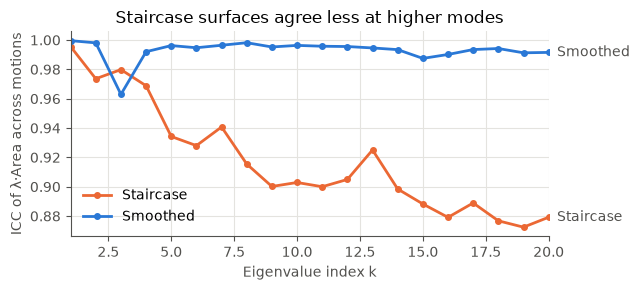

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3))
k = np.arange(1, 21)
for s, c, name in ((STAIR, ORANGE, "Staircase"), (SMOOTH, BLUE, "Smoothed")):
    y = [icc(na[:, s, :5, i]) for i in k]; ax.plot(k, y, color=c, lw=2, marker="o", ms=4, label=name)
    ax.annotate(name, (20, y[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
ax.set(xlabel="Eigenvalue index k", ylabel="ICC of λ·Area across motions", title="Staircase surfaces agree less at higher modes", xlim=(1, 20))
ax.legend(frameon=False, loc="lower left"); plt.tight_layout(); plt.show()

### Grid resolution: Proposition 3

Coarsening the grid from 0.4 to 0.8 mm should leave $\lambda\cdot$Area alone and multiply $\operatorname{eig}(L)$ by about the drop in vertex count.

In [6]:
rows = {}
for s, name in ((STAIR, "Staircase"), (SMOOTH, "Smoothed")):
    rows[name + ": λ·Area, 0.8 / 0.4 mm"] = [np.median(na[:, s, COARSE, k] / na[:, s, 0, k]) for k in ks]
    rows[name + ": eig(L), 0.8 / 0.4 mm"] = [np.median(lam_l[:, s, COARSE, k] / lam_l[:, s, 0, k]) for k in ks]
    rows[name + ": eig(L)·n / (λ·Area)"] = [np.median(lam_l[:, s, 0, k] * n[:, s, 0] / na[:, s, 0, k]) for k in ks]
print("median vertex ratio, 0.4 / 0.8 mm:", np.round(np.median(n[:, :, 0] / n[:, :, COARSE], 0), 2))
pd.DataFrame(rows, index=[f"k={k}" for k in ks]).T.round(3)

median vertex ratio, 0.4 / 0.8 mm: [4.71 4.05]


,k=1,k=2,k=5,k=10,k=20
"Staircase: λ·Area, 0.8 / 0.4 mm",0.994,1.042,1.024,1.017,1.009
"Staircase: eig(L), 0.8 / 0.4 mm",4.663,4.866,4.801,4.780,4.710
Staircase: eig(L)·n / (λ·Area),0.999,0.998,0.997,0.996,0.994
"Smoothed: λ·Area, 0.8 / 0.4 mm",0.999,1.002,0.997,0.992,0.981
"Smoothed: eig(L), 0.8 / 0.4 mm",4.032,4.060,4.028,4.004,3.956
Smoothed: eig(L)·n / (λ·Area),0.999,1.000,0.996,0.996,0.995


### The stored ESWA eigenvalues

In [7]:
vol = volume[:, SMOOTH, 0]
print("lesions whose stored spectrum has an extra zero mode, shifting its indices:", (eswa[:, 1] < 1e-9).sum(), "of", len(eswa))
idx = [1, 5, 20, 50, 99]
pd.DataFrame({"Spearman with native vertex count": [spearmanr(eswa[:, k], native_n)[0] for k in idx],
              "Spearman with volume": [spearmanr(eswa[:, k], vol)[0] for k in idx]}, index=[f"k={k}" for k in idx]).round(3)

lesions whose stored spectrum has an extra zero mode, shifting its indices: 29 of 200


,Spearman with native vertex count,Spearman with volume
k=1,-0.914,-0.883
k=5,-0.993,-0.973
k=20,-0.998,-0.978
k=50,-0.999,-0.982
k=99,-1.000,-0.983


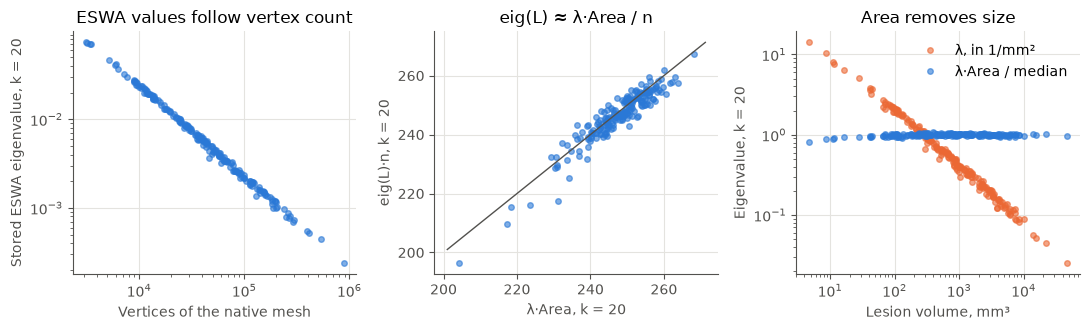

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
ax[0].loglog(native_n, eswa[:, 20], "o", ms=4, color=BLUE, alpha=.6)
ax[0].set(xlabel="Vertices of the native mesh", ylabel="Stored ESWA eigenvalue, k = 20", title="ESWA values follow vertex count")
ax[1].plot(na[:, SMOOTH, 0, 20], lam_l[:, SMOOTH, 0, 20] * n[:, SMOOTH, 0], "o", ms=4, color=BLUE, alpha=.6)
lim = ax[1].get_xlim(); ax[1].plot(lim, lim, color=INK, lw=1); ax[1].set(xlabel="λ·Area, k = 20", ylabel="eig(L)·n, k = 20", title="eig(L) ≈ λ·Area / n")
ax[2].semilogx(vol, lam[:, SMOOTH, 0, 20], "o", ms=4, color=ORANGE, alpha=.6, label="λ, in 1/mm²")
ax[2].set_yscale("log"); ax[2].semilogx(vol, na[:, SMOOTH, 0, 20] / np.median(na[:, SMOOTH, 0, 20]), "o", ms=4, color=BLUE, alpha=.6, label="λ·Area / median")
ax[2].set(xlabel="Lesion volume, mm³", ylabel="Eigenvalue, k = 20", title="Area removes size"); ax[2].legend(frameon=False)
plt.tight_layout(); plt.savefig("../docs/assets/lb-invariance.png", dpi=160); plt.show()

### Is there shape signal once size is removed?

Train+Validation only (130). AUC per feature with a bootstrap CI, then logistic regression on the first 20 eigenvalues, five-fold, repeated 20 times.

In [9]:
tv = ~d["test"]; y = d["y"][tv]
mean_na = na[:, SMOOTH, :5].mean(1)
raw = dict(zip(["Volume", "Native vertex count"], [vol, native_n]))
for k in (1, 5, 20):
    raw[f"λ·Area, k={k}"] = mean_na[:, k]; raw[f"Stored ESWA, k={k} (negated)"] = -eswa[:, k]
print(pd.Series({name: "{:.3f} [{:.3f}, {:.3f}]".format(roc_auc_score(y, v[tv]), *auc_ci(y, v[tv])) for name, v in raw.items()}).to_string())
def cv(X):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    r = [roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="decision_function")) for s in range(20)]
    return round(np.mean(r), 3), round(np.std(r), 3)
log_na, log_v = np.log(mean_na[tv, 1:]), np.log(vol[tv, None])
pd.DataFrame({"Volume": cv(log_v), "λ·Area, k=1-20": cv(log_na), "Volume + λ·Area": cv(np.c_[log_v, log_na]),
              "Stored ESWA, k=1-20": cv(np.log(np.maximum(eswa[tv, 1:21], 1e-9)))}, index=["CV AUC", "SD over repeats"]).T

Volume                         0.722 [0.633, 0.808]
Native vertex count            0.725 [0.638, 0.807]
λ·Area, k=1                    0.590 [0.492, 0.683]
Stored ESWA, k=1 (negated)     0.718 [0.628, 0.798]
λ·Area, k=5                    0.481 [0.385, 0.583]
Stored ESWA, k=5 (negated)     0.733 [0.647, 0.816]
λ·Area, k=20                   0.565 [0.460, 0.666]
Stored ESWA, k=20 (negated)    0.727 [0.641, 0.810]


,CV AUC,SD over repeats
Volume,0.710,0.005
"λ·Area, k=1-20",0.591,0.026
Volume + λ·Area,0.652,0.023
"Stored ESWA, k=1-20",0.723,0.006


**Reading these results.**

- The stored ESWA features score like volume because they measure it. This does not make the ESWA result wrong as a classifier; it changes what the result means. Those values also depend on the voxel grid, so they would shift on data from another scanner setting.
- Adding $\lambda\cdot$Area to volume lowers the cross-validated AUC here, so these 20 modes add noise rather than signal in a linear model on 130 lesions.
- This is one linear model on low modes of one smoothing level. Smoothing at 0.8 mm may remove the spiculation that higher modes would need to see.

## 5. Protocol

Lesions: all 200 for invariance; labels on the 130 Train+Validation lesions only, so Test stays clean for the final descriptors. Malignant is positive. Motion seeds are fixed per lesion and a rerun matched the stored eigenvalues to about 4e-12. No training, so no Kaggle kernel; stored results: `results/lb-invariance/spectra.npz`. The challenge benchmark does not apply: this produces no predictions.

## 6. Open issues

- **Higher modes and less smoothing.** Does signal appear beyond $k=20$, or at a lighter smoothing? Needs the higher-frequency stability step, since those modes are also the least stable.
- **Effect on the ESWA ensemble.** Replacing the stored values with $\lambda\cdot$Area in the full dual-path model has not been run ([#28](https://github.com/mralinp/abus-classification/issues/28)).
- **Isometry on lesions.** Tested exactly on meshes, not on real tissue. Whether lesions deform near-isometrically between acquisitions cannot be measured here: TDSC-ABUS has one scan per lesion.
- **Anisotropy.** Lesions were resampled from a 0.476 mm slice spacing, so all renders share that loss; the stability step should measure it.